<a href="https://colab.research.google.com/github/Razae786/NLP-Lab-FA23-BAI-064/blob/main/NLP_Lab_06_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP Lab 6: Text Classification
## Naive Bayes and Logistic Regression

This Colab notebook contains Activity 1 to Activity 5 and Stage v verification tasks.

The notebook is written to be beginner-friendly and avoids the data leakage problem that can happen when TF-IDF is fitted before the train/test split.


## Step 0. Upload the dataset

For Activities 1 to 5, upload the movie review CSV.

The CSV should contain two columns:
- `text`
- `label`

The label values should normally be `positive` and `negative`.


In [ ]:
# Upload your movie_reviews.csv file
from google.colab import files
import pandas as pd
import os

uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Please upload a CSV file.")

file_name = csv_files[0]
df = pd.read_csv(file_name)

print("Loaded file:", file_name)
print("Shape:", df.shape)
print("Columns:", list(df.columns))

# Check required columns
required_columns = {"text", "label"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required column(s): {sorted(missing)}. "
        "Your CSV must contain columns named 'text' and 'label'."
    )

# Clean basic missing values
df = df[["text", "label"]].dropna().copy()
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(str).str.strip()

print("\nFirst 5 rows:")
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())


Saving movie_reviews.csv to movie_reviews.csv
Loaded file: movie_reviews.csv
Shape: (20, 2)
Columns: ['text', 'label']

First 5 rows:


,text,label
0,"I absolutely loved this movie, the acting was ...",positive
1,This was a fantastic film with a great story.,positive
2,The movie was boring and far too long.,negative
3,"I hated this movie, it was a complete waste of...",negative
4,Excellent acting and a very enjoyable story.,positive



Class distribution:
label
positive    10
negative    10
Name: count, dtype: int64


# Activity 1
## Bag of Words using CountVectorizer

Goal:
Convert review text into numerical vectors using word counts.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Create the Bag of Words vectorizer
bow_vectorizer = CountVectorizer()

# Learn the vocabulary and convert all reviews into vectors
X_bow = bow_vectorizer.fit_transform(df["text"])

# Vocabulary size
print("Vocabulary size:", len(bow_vectorizer.vocabulary_))

# Show some vocabulary words
print("\nFirst 20 vocabulary items:")
print(list(bow_vectorizer.vocabulary_.items())[:20])

# Show first 5 documents and first 10 features
rows = min(5, X_bow.shape[0])
cols = min(10, X_bow.shape[1])

print(f"\nSparse matrix shape: {X_bow.shape}")
print(f"\nSparse matrix portion: first {rows} documents, first {cols} features")
print(X_bow[:rows, :cols].toarray())


Vocabulary size: 71

First 20 vocabulary items:
[('absolutely', 0), ('loved', 38), ('this', 55), ('movie', 40), ('the', 54), ('acting', 1), ('was', 60), ('excellent', 25), ('fantastic', 27), ('film', 30), ('with', 66), ('great', 32), ('story', 51), ('boring', 10), ('and', 5), ('far', 28), ('too', 58), ('long', 37), ('hated', 33), ('it', 36)]

Sparse matrix shape: (20, 71)

Sparse matrix portion: first 5 documents, first 10 features
[[1 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 1 0 0 0 1 0 0 0 0]]


### Activity 1 explanation

`CountVectorizer()` creates the Bag of Words representation.

`fit_transform()` does two things:
1. Learns the vocabulary.
2. Converts each review into a vector of word counts.

The matrix is sparse because most documents contain only a small part of the complete vocabulary.


# Activity 2
## TF-IDF representation

Goal:
Compare raw word counts with TF-IDF values.

The original lab uses common words such as `the` and `was`. This version safely chooses them if they exist. If they do not exist, it automatically chooses common words that exist in the dataset.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Build TF-IDF representation
tfidf_vectorizer_full = TfidfVectorizer()
X_tfidf_full = tfidf_vectorizer_full.fit_transform(df["text"])

print("TF-IDF matrix shape:", X_tfidf_full.shape)

# Choose a document safely
doc_index = 1 if len(df) > 1 else 0

# Prefer the words from the lab
preferred_words = ["the", "was"]

# Check which preferred words exist
available_preferred = [
    word for word in preferred_words
    if word in tfidf_vectorizer_full.vocabulary_
]

# If they are missing, choose two common vocabulary words
if len(available_preferred) < 2:
    word_counts = X_bow.sum(axis=0).A1
    vocab_items = list(bow_vectorizer.vocabulary_.items())

    sorted_words = sorted(
        vocab_items,
        key=lambda item: word_counts[item[1]],
        reverse=True
    )

    fallback_words = [word for word, _ in sorted_words[:5]]

    for word in fallback_words:
        if word not in available_preferred:
            available_preferred.append(word)
        if len(available_preferred) == 2:
            break

word1, word2 = available_preferred[:2]

print("Document used:", doc_index)
print("Review:", df.loc[df.index[doc_index], "text"])
print("\nWords compared:", word1, "and", word2)

# Important: each vectorizer has its own vocabulary mapping.
bow_idx1 = bow_vectorizer.vocabulary_[word1]
bow_idx2 = bow_vectorizer.vocabulary_[word2]

tfidf_idx1 = tfidf_vectorizer_full.vocabulary_[word1]
tfidf_idx2 = tfidf_vectorizer_full.vocabulary_[word2]

raw_count_1 = X_bow[doc_index, bow_idx1]
raw_count_2 = X_bow[doc_index, bow_idx2]

tfidf_value_1 = X_tfidf_full[doc_index, tfidf_idx1]
tfidf_value_2 = X_tfidf_full[doc_index, tfidf_idx2]

print(f"\n'{word1}'")
print("Raw count:", raw_count_1)
print("TF-IDF:", round(float(tfidf_value_1), 4))

print(f"\n'{word2}'")
print("Raw count:", raw_count_2)
print("TF-IDF:", round(float(tfidf_value_2), 4))

print(
    "\nExplanation: A word that appears in many documents receives "
    "a lower IDF value, so its TF-IDF weight is reduced."
)


TF-IDF matrix shape: (20, 71)
Document used: 1
Review: This was a fantastic film with a great story.

Words compared: the and was

'the'
Raw count: 0
TF-IDF: 0.0

'was'
Raw count: 1
TF-IDF: 0.2452

Explanation: A word that appears in many documents receives a lower IDF value, so its TF-IDF weight is reduced.


# Activity 3
## Train Naive Bayes and Logistic Regression

Important improvement:
For a correct machine learning experiment, we split the raw text first. The TF-IDF vectorizer is fitted only on the training text.

This prevents test-set information from leaking into training.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Raw text and labels
X_text = df["text"]
y = df["label"]

# Split raw text before fitting TF-IDF
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

# Naive Bayes pipeline
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", MultinomialNB())
])

# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
])

# Train both models
nb_pipeline.fit(X_train_text, y_train)
lr_pipeline.fit(X_train_text, y_train)

# Predictions
nb_preds = nb_pipeline.predict(X_test_text)
lr_preds = lr_pipeline.predict(X_test_text)

print("\nNaive Bayes and Logistic Regression training completed.")
print("Predictions generated successfully.")


Training samples: 16
Testing samples: 4

Naive Bayes and Logistic Regression training completed.
Predictions generated successfully.


# Activity 4
## Evaluate both classifiers

We calculate:
- Accuracy
- Precision
- Recall
- F1 score
- Confusion matrix

The code automatically identifies the positive class. If the dataset contains `positive`, it uses that. Otherwise, it uses the second sorted class.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Identify class labels
classes = sorted(y.unique().tolist())

if "positive" in classes:
    positive_label = "positive"
else:
    positive_label = classes[-1]

print("Classes:", classes)
print("Positive class used for precision/recall/F1:", positive_label)

def evaluate_model(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred,
        pos_label=positive_label,
        zero_division=0
    )
    recall = recall_score(
        y_true, y_pred,
        pos_label=positive_label,
        zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred,
        pos_label=positive_label,
        zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred, labels=classes)

    print(f"\n--- {model_name} ---")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print("\nConfusion Matrix:")
    print(cm)

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm
    }

nb_results = evaluate_model("Naive Bayes", y_test, nb_preds)
lr_results = evaluate_model("Logistic Regression", y_test, lr_preds)


Classes: ['negative', 'positive']
Positive class used for precision/recall/F1: positive

--- Naive Bayes ---
Accuracy : 0.5000
Precision: 0.5000
Recall   : 1.0000
F1 Score : 0.6667

Confusion Matrix:
[[0 2]
 [0 2]]

--- Logistic Regression ---
Accuracy : 0.5000
Precision: 0.5000
Recall   : 1.0000
F1 Score : 0.6667

Confusion Matrix:
[[0 2]
 [0 2]]


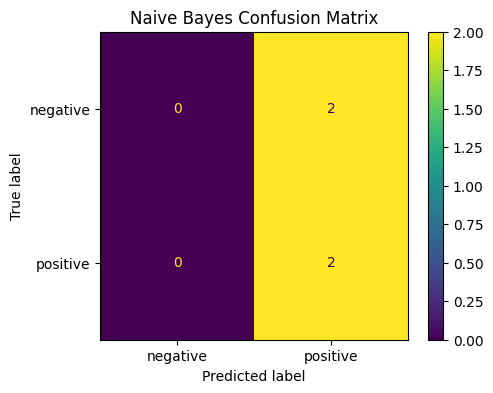

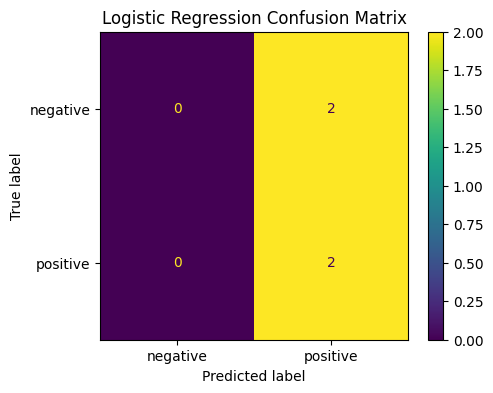

In [ ]:
# Display confusion matrices

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=nb_results["confusion_matrix"],
    display_labels=classes
).plot(ax=ax)
ax.set_title("Naive Bayes Confusion Matrix")
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=lr_results["confusion_matrix"],
    display_labels=classes
).plot(ax=ax)
ax.set_title("Logistic Regression Confusion Matrix")
plt.show()


# Activity 5
## Build a complete Pipeline and classify new reviews

A Pipeline keeps the TF-IDF vectorizer and classifier together.

The pipeline receives raw text and automatically performs:
text → TF-IDF → classifier → prediction


In [ ]:
# Select the better-performing model based on F1 score
if lr_results["f1"] >= nb_results["f1"]:
    best_classifier = LogisticRegression(max_iter=1000)
    best_name = "Logistic Regression"
else:
    best_classifier = MultinomialNB()
    best_name = "Naive Bayes"

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", best_classifier)
])

# Train on raw training text
final_pipeline.fit(X_train_text, y_train)

print("Selected classifier:", best_name)
print("Pipeline trained successfully.")


Selected classifier: Logistic Regression
Pipeline trained successfully.


In [ ]:
# Create three new reviews
new_reviews = [
    "The movie was excellent and I really enjoyed it.",
    "This was boring and a complete waste of time.",
    "The acting was good but the story was weak."
]

new_predictions = final_pipeline.predict(new_reviews)

print("Predictions:\n")

for review, prediction in zip(new_reviews, new_predictions):
    print("Review:", review)
    print("Prediction:", prediction)
    print()


Predictions:

Review: The movie was excellent and I really enjoyed it.
Prediction: positive

Review: This was boring and a complete waste of time.
Prediction: negative

Review: The acting was good but the story was weak.
Prediction: positive



# Stage v: Verification

Stage v uses an app review dataset.

For Stage v, upload the app review CSV when asked.

It should contain:
- `text`
- `label`

The following activities use a proper train/test split and a Pipeline.


In [ ]:
# Upload the app review dataset for Stage v
print("Upload the app review CSV for Stage v.")

uploaded_stage_v = files.upload()

csv_files_v = [
    name for name in uploaded_stage_v.keys()
    if name.lower().endswith(".csv")
]

if not csv_files_v:
    raise FileNotFoundError("Please upload the app review CSV file.")

app_file = csv_files_v[0]
app_df = pd.read_csv(app_file)

print("Loaded:", app_file)
print("Shape:", app_df.shape)
print("Columns:", list(app_df.columns))

required = {"text", "label"}
missing = required - set(app_df.columns)

if missing:
    raise ValueError(
        f"Missing required column(s): {sorted(missing)}. "
        "The app review CSV must contain 'text' and 'label'."
    )

app_df = app_df[["text", "label"]].dropna().copy()
app_df["text"] = app_df["text"].astype(str)
app_df["label"] = app_df["label"].astype(str).str.strip()

print("\nClass distribution:")
print(app_df["label"].value_counts())


Upload the app review CSV for Stage v.


Saving app_reviews.csv to app_reviews.csv
Loaded: app_reviews.csv
Shape: (20, 2)
Columns: ['text', 'label']

Class distribution:
label
positive    10
negative    10
Name: count, dtype: int64


## Stage v Activity 1

Build a full Pipeline using TF-IDF and Logistic Regression.

Report accuracy, precision, recall, and F1 on the held-out test set.


In [ ]:
# Stage v Activity 1

X_app = app_df["text"]
y_app = app_df["label"]

app_classes = sorted(y_app.unique().tolist())

if "negative" in app_classes:
    negative_label = "negative"
else:
    negative_label = app_classes[0]

if "positive" in app_classes:
    app_positive_label = "positive"
else:
    app_positive_label = app_classes[-1]

X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(
    X_app,
    y_app,
    test_size=0.2,
    random_state=42,
    stratify=y_app
)

app_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
])

app_pipeline.fit(X_app_train, y_app_train)

app_preds = app_pipeline.predict(X_app_test)

app_accuracy = accuracy_score(y_app_test, app_preds)
app_precision = precision_score(
    y_app_test, app_preds,
    pos_label=app_positive_label,
    zero_division=0
)
app_recall = recall_score(
    y_app_test, app_preds,
    pos_label=app_positive_label,
    zero_division=0
)
app_f1 = f1_score(
    y_app_test, app_preds,
    pos_label=app_positive_label,
    zero_division=0
)

print("Stage v Activity 1 Results")
print(f"Accuracy : {app_accuracy:.4f}")
print(f"Precision: {app_precision:.4f}")
print(f"Recall   : {app_recall:.4f}")
print(f"F1 Score : {app_f1:.4f}")


Stage v Activity 1 Results
Accuracy : 0.7500
Precision: 1.0000
Recall   : 0.5000
F1 Score : 0.6667


## Stage v Activity 2

Plot the confusion matrix and inspect which class has more mistakes.

Use the matrix together with recall and precision to explain model weaknesses.


Class order: ['negative', 'positive']

Confusion Matrix:
[[2 0]
 [1 1]]


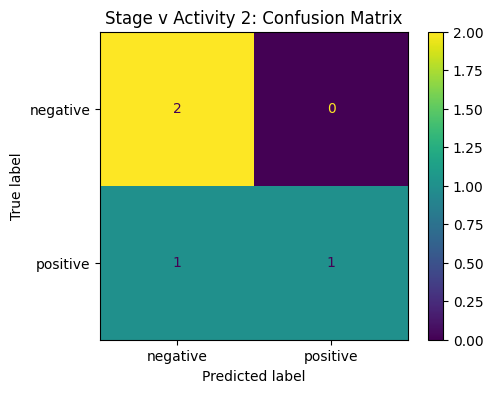

The class with the most misclassified examples is: positive


In [ ]:
# Stage v Activity 2

app_cm = confusion_matrix(
    y_app_test,
    app_preds,
    labels=app_classes
)

print("Class order:", app_classes)
print("\nConfusion Matrix:")
print(app_cm)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=app_cm,
    display_labels=app_classes
).plot(ax=ax)

ax.set_title("Stage v Activity 2: Confusion Matrix")
plt.show()

# Find the class with the largest number of errors
error_counts = {}

for i, class_name in enumerate(app_classes):
    row_total = app_cm[i].sum()
    correct = app_cm[i, i]
    error_counts[class_name] = row_total - correct

most_errors_class = max(error_counts, key=error_counts.get)

print(
    f"The class with the most misclassified examples is: "
    f"{most_errors_class}"
)


## Stage v Activity 3

Create a DataFrame containing every misclassified example.

Required columns:
- text
- true_label
- predicted_label
- predicted_probability

Then sort by predicted probability and show the top 5 most confident wrong predictions.

For a binary classifier, the probability stored here is the probability assigned to the predicted class.


In [ ]:
# Stage v Activity 3

# Get probability for every class
probabilities = app_pipeline.predict_proba(X_app_test)
class_names_from_model = list(app_pipeline.named_steps["clf"].classes_)

misclassified_rows = []

for text, true_label, predicted_label, prob_vector in zip(
    X_app_test,
    y_app_test,
    app_preds,
    probabilities
):
    if true_label != predicted_label:
        predicted_index = class_names_from_model.index(predicted_label)
        predicted_probability = prob_vector[predicted_index]

        misclassified_rows.append({
            "text": text,
            "true_label": true_label,
            "predicted_label": predicted_label,
            "predicted_probability": predicted_probability
        })

misclassified_df = pd.DataFrame(misclassified_rows)

if misclassified_df.empty:
    print("No misclassified examples were found on this test split.")
else:
    misclassified_df = misclassified_df.sort_values(
        by="predicted_probability",
        ascending=False
    )

    print("Top 5 most confident wrong predictions:")
    display(misclassified_df.head(5))


Top 5 most confident wrong predictions:


,text,true_label,predicted_label,predicted_probability
0,Excellent app with a clean and simple interface.,positive,negative,0.505995


## Stage v Activity 4

First inspect class distribution.

Then train a balanced Logistic Regression model using:
`class_weight='balanced'`

Finally compare precision, recall, and F1 for the negative class before and after balancing.


In [ ]:
# Stage v Activity 4

print("Original class distribution:")
print(app_df["label"].value_counts())

# Original model metrics for the negative class
original_negative_precision = precision_score(
    y_app_test,
    app_preds,
    pos_label=negative_label,
    zero_division=0
)

original_negative_recall = recall_score(
    y_app_test,
    app_preds,
    pos_label=negative_label,
    zero_division=0
)

original_negative_f1 = f1_score(
    y_app_test,
    app_preds,
    pos_label=negative_label,
    zero_division=0
)

# Balanced model
balanced_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

balanced_pipeline.fit(X_app_train, y_app_train)

balanced_preds = balanced_pipeline.predict(X_app_test)

balanced_negative_precision = precision_score(
    y_app_test,
    balanced_preds,
    pos_label=negative_label,
    zero_division=0
)

balanced_negative_recall = recall_score(
    y_app_test,
    balanced_preds,
    pos_label=negative_label,
    zero_division=0
)

balanced_negative_f1 = f1_score(
    y_app_test,
    balanced_preds,
    pos_label=negative_label,
    zero_division=0
)

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1"],
    "Original Model": [
        original_negative_precision,
        original_negative_recall,
        original_negative_f1
    ],
    "Balanced Model": [
        balanced_negative_precision,
        balanced_negative_recall,
        balanced_negative_f1
    ]
})

print("\nNegative-class comparison:")
display(comparison)


Original class distribution:
label
positive    10
negative    10
Name: count, dtype: int64

Negative-class comparison:


,Metric,Original Model,Balanced Model
0,Precision,0.666667,0.666667
1,Recall,1.000000,1.000000
2,F1,0.800000,0.800000


## Stage v Activity 5

Business problem:
Automatically flag negative customer reviews so the support team can respond first.

The lab asks you to run the model on new unseen feedback snippets.

The source file does not contain the actual unseen snippets in the extracted text, so this cell uses three clearly marked example snippets. Replace them with the exact snippets provided by your instructor if they appear elsewhere in your lab material.


In [ ]:
# Stage v Activity 5

new_customer_feedback = [
    "The application crashes every time I try to log in.",
    "I really like the new update. Everything works smoothly.",
    "The service is slow and the latest update made things worse."
]

feedback_predictions = app_pipeline.predict(new_customer_feedback)

# Get probability of the predicted class
feedback_probabilities = app_pipeline.predict_proba(new_customer_feedback)
model_classes = list(app_pipeline.named_steps["clf"].classes_)

print("Customer feedback results:\n")

for feedback, prediction, prob_vector in zip(
    new_customer_feedback,
    feedback_predictions,
    feedback_probabilities
):
    predicted_index = model_classes.index(prediction)
    confidence = prob_vector[predicted_index]

    flag = "FLAG AS NEGATIVE" if prediction == negative_label else "DO NOT FLAG"

    print("Feedback:", feedback)
    print("Prediction:", prediction)
    print("Confidence:", f"{confidence:.2%}")
    print("Action:", flag)
    print()


Customer feedback results:

Feedback: The application crashes every time I try to log in.
Prediction: negative
Confidence: 57.62%
Action: FLAG AS NEGATIVE

Feedback: I really like the new update. Everything works smoothly.
Prediction: positive
Confidence: 55.33%
Action: DO NOT FLAG

Feedback: The service is slow and the latest update made things worse.
Prediction: negative
Confidence: 60.12%
Action: FLAG AS NEGATIVE



## Stage v Activity 5 Recommendation

Use your actual negative-class precision and recall from Activity 4.

A suitable interpretation is:

The model can be useful as a first-pass filter for customer support, but it should not be treated as a perfect automatic decision system. Precision tells us how many reviews flagged as negative are actually negative. Recall tells us how many actual negative reviews the model successfully catches. If recall is low, the system will miss many negative reviews. If precision is low, support staff will receive too many false alerts. The model should therefore be monitored and improved using real support feedback.
